# SE4042 · Topic 4 Lab · Part 1 — Rules with day jobs + the boundary experiment

Starter code: **Listing 4.1** (Chapter 4, §4.3), extended with a `periodic` flag.

* **Part 1** — reproduce the four space–time diagrams of Figure 4.2 (Rules 30, 90, 110, 184).
* **Task 1.1** — the boundary experiment: Rule 184, 250 steps, 201 cells, fixed vs periodic.
* **Task 1.2** — the light cone: the same comparison for Rule 30.

In [12]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

## Listing 4.1, with a boundary switch

The chapter's loop runs over `range(1, width - 1)` only, so the two edge cells are never
updated and stay 0 — **fixed all-dead boundaries**. With `periodic=True` every cell is
updated and the neighbours are read with modulo indexing, so the line becomes a **ring**.
The update stays synchronous: row `t+1` is computed only from row `t`.

In [13]:
def elementary_ca(rule_num, width=201, steps=100, periodic=False):
    """Simulate a 1-D elementary cellular automaton (Wolfram numbering).

    periodic=False : fixed all-dead edges (Listing 4.1 as printed)
    periodic=True  : ring — neighbours wrap around with modulo indexing
    """
    rule_bin = format(rule_num, "08b")                       # 8-bit rule number
    rule_map = {tuple(int(b) for b in format(7 - i, "03b")): int(rule_bin[i])
                for i in range(8)}                           # neighbourhood -> next state
    grid = np.zeros((steps, width), dtype=int)
    grid[0, width // 2] = 1                                  # single live seed in the centre
    for t in range(steps - 1):
        if periodic:
            for i in range(width):                           # every cell, wrap at the ends
                grid[t+1, i] = rule_map[(grid[t, (i - 1) % width],
                                         grid[t, i],
                                         grid[t, (i + 1) % width])]
        else:
            for i in range(1, width - 1):                    # interior only: fixed all-dead edges
                grid[t+1, i] = rule_map[(grid[t, i-1], grid[t, i], grid[t, i+1])]
    return grid


def show(ax, grid, title):
    ax.imshow(grid, cmap="binary", interpolation="nearest", aspect="auto")
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("cell index")
    ax.set_ylabel("time step")

## Part 1 — Reproduce Listing 4.1's output and Figure 4.2

Expected (self-check table): cumulative live-cell counts **5196 / 1251 / 2876 / 100**.

Rule  30:  5196 live cells summed over all 100 rows   [OK]
Rule  90:  1251 live cells summed over all 100 rows   [OK]
Rule 110:  2876 live cells summed over all 100 rows   [OK]
Rule 184:   100 live cells summed over all 100 rows   [OK]


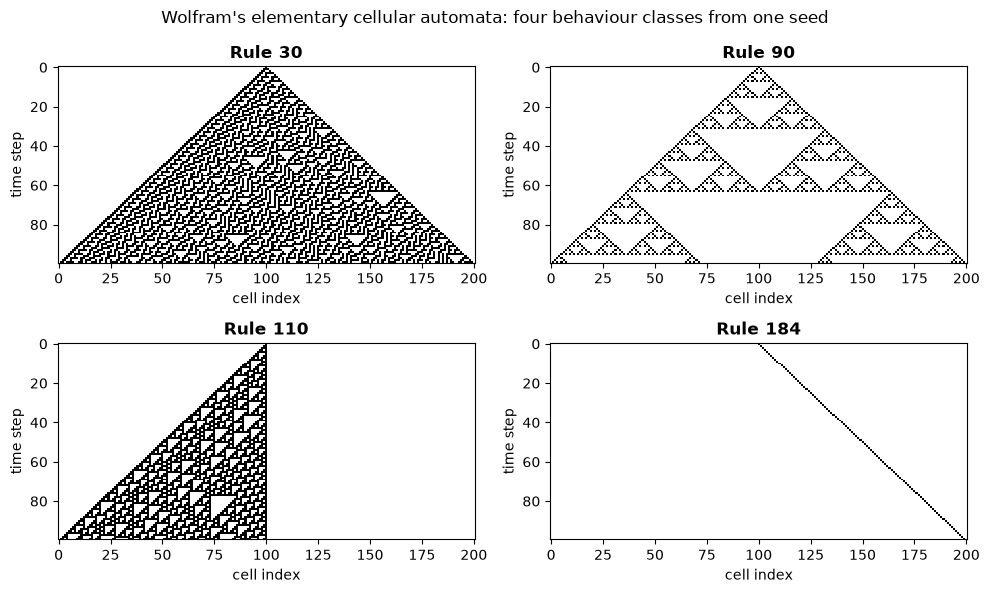

In [14]:
RULES = [30, 90, 110, 184]
EXPECTED = {30: 5196, 90: 1251, 110: 2876, 184: 100}

grids = {}
for rule in RULES:                                           # one from each flavour
    g = elementary_ca(rule, 201, 100)
    grids[rule] = g
    status = "OK" if g.sum() == EXPECTED[rule] else f"MISMATCH (expected {EXPECTED[rule]})"
    print(f"Rule {rule:>3}: {g.sum():>5} live cells summed over all 100 rows   [{status}]")

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, rule in zip(axes.flat, RULES):
    show(ax, grids[rule], f"Rule {rule}")
fig.suptitle("Wolfram's elementary cellular automata: four behaviour classes from one seed")
fig.tight_layout()
fig.savefig("fig1_four_rules.png", dpi=150)
plt.show()

### Rules in the wild

* **Rule 30** — Class III chaos; shipped as Mathematica's default random-number generator, and
  the same kind of pattern is printed on the shell of the cone snail *Conus textile*.
* **Rule 90** — each cell is the XOR of its neighbours, i.e. Pascal's triangle mod 2, so it
  draws the Sierpiński fractal (error-correcting codes, binomial coefficients, fractal antennas).
* **Rule 110** — Class IV; weakly Turing complete. Its gliders are the wires.
* **Rule 184** — the minimal traffic model (Nagel–Schreckenberg with v_max = 1, p = 0): the
  single "car" just drifts one cell right per step and is never created or destroyed.

## Task 1.1 — The boundary experiment (Rule 184, 201 cells, 250 steps)

**Prediction (before running).** Rule 184 moves the lone seed one cell to the right every step.
It starts at index 100, so at step *t* it sits at index 100 + *t*.

* **Fixed edges:** the last updatable cell is index 199 (reached at step 99). At step 100 the seed
  would move onto index 200, but the edge cell is never updated and is held dead — so the seed
  is absorbed by the wall and the line is all-dead from step 100 onward.
* **Periodic ring:** nothing absorbs it; it wraps from index 200 back to 0 and keeps drifting.
  After 249 steps it should be at (100 + 249) mod 201 = **148**, still exactly one live cell.

Fixed boundary : seed vanishes at step 100 (live cells at step 99 = 1, step 100 = 0); stays dead afterwards: True
Periodic ring  : exactly one live cell at every step: True
Periodic ring  : after 249 steps the live cell is at index 148  (expected (100 + 249) mod 201 = 148)


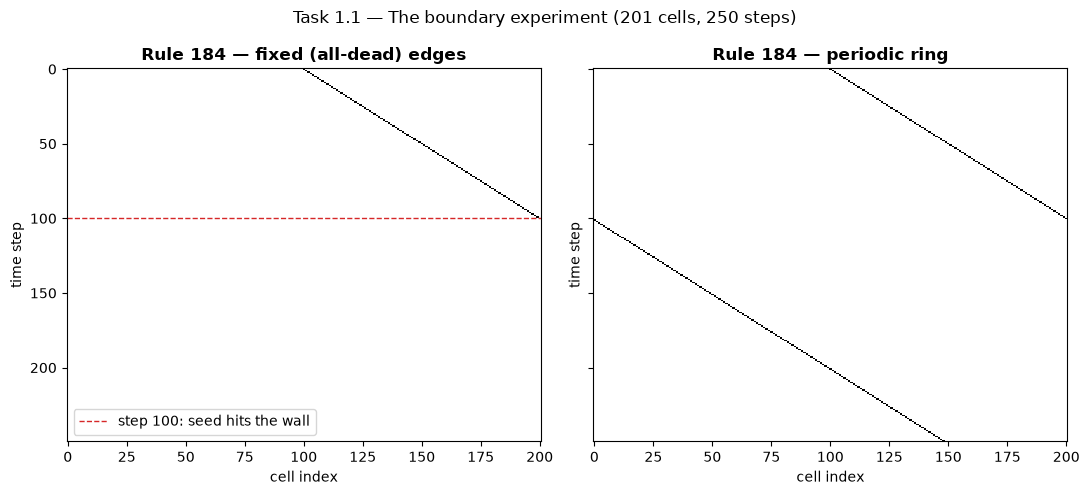

In [15]:
STEPS = 250
fixed_184 = elementary_ca(184, 201, STEPS, periodic=False)
ring_184 = elementary_ca(184, 201, STEPS, periodic=True)

# --- self-checks -----------------------------------------------------------
pop_fixed = fixed_184.sum(axis=1)
pop_ring = ring_184.sum(axis=1)
vanish_step = int(np.argmax(pop_fixed == 0))                 # first all-dead row
print(f"Fixed boundary : seed vanishes at step {vanish_step} "
      f"(live cells at step 99 = {pop_fixed[99]}, step 100 = {pop_fixed[100]}); "
      f"stays dead afterwards: {bool(np.all(pop_fixed[vanish_step:] == 0))}")
print(f"Periodic ring  : exactly one live cell at every step: {bool(np.all(pop_ring == 1))}")
print(f"Periodic ring  : after {STEPS - 1} steps the live cell is at index "
      f"{int(np.flatnonzero(ring_184[-1])[0])}  (expected (100 + 249) mod 201 = {(100 + 249) % 201})")

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
show(axes[0], fixed_184, "Rule 184 — fixed (all-dead) edges")
show(axes[1], ring_184, "Rule 184 — periodic ring")
axes[0].axhline(vanish_step, color="tab:red", lw=1, ls="--", label=f"step {vanish_step}: seed hits the wall")
axes[0].legend(loc="lower left")
fig.suptitle("Task 1.1 — The boundary experiment (201 cells, 250 steps)")
fig.tight_layout()
fig.savefig("fig2_rule184_boundary.png", dpi=150)
plt.show()

**Observation.** The prediction holds exactly. With fixed edges the "car" drives into the wall and
disappears at step 100 — the boundary *destroys* the conserved quantity that makes Rule 184 a
traffic model. On the ring the car count is conserved forever (one live cell in every row) and the
seed reappears on the left after crossing the right edge, ending at index 148 after 249 steps.

## Task 1.2 — The light cone (Rule 30, 201 cells, 250 steps)

Rows identical for steps 0..99: True
First step where fixed and periodic differ: 100
Rows that differ from then on: 150 of 150
Leftmost live cell at step 99: 1  (the cone is 1 cell from the wall)


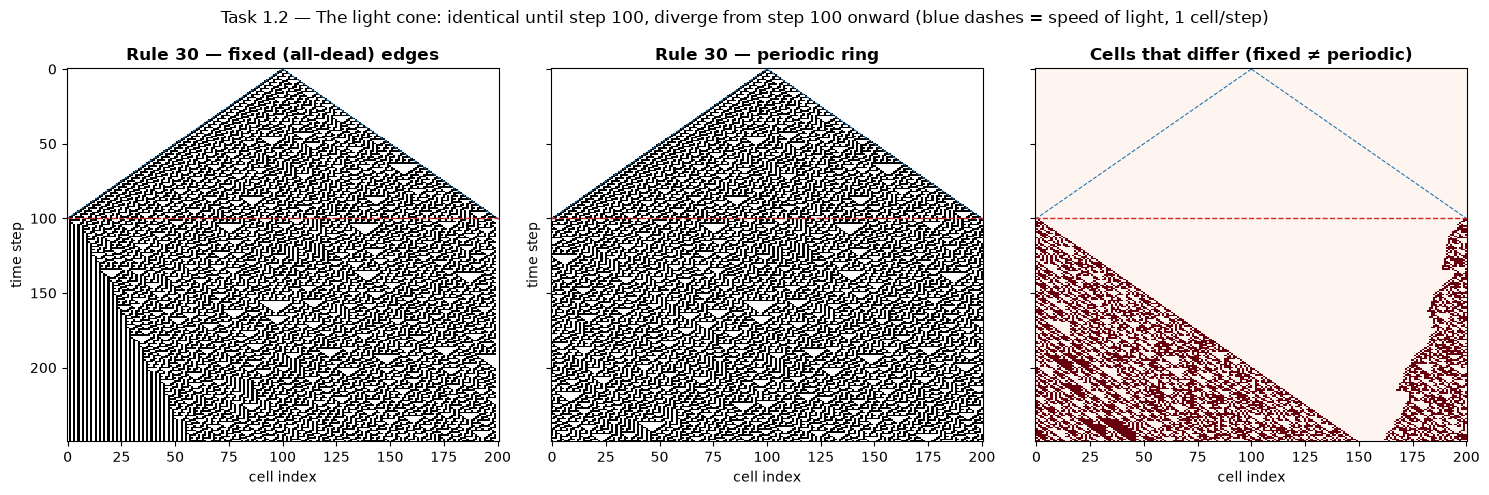

In [16]:
fixed_30 = elementary_ca(30, 201, STEPS, periodic=False)
ring_30 = elementary_ca(30, 201, STEPS, periodic=True)

row_differs = np.any(fixed_30 != ring_30, axis=1)
first_diff = int(np.argmax(row_differs))
print(f"Rows identical for steps 0..{first_diff - 1}: {bool(not row_differs[:first_diff].any())}")
print(f"First step where fixed and periodic differ: {first_diff}")
print(f"Rows that differ from then on: {int(row_differs[first_diff:].sum())} of {STEPS - first_diff}")

# light-cone edge: the leftmost / rightmost live cell of the fixed run
left_edge = [int(np.flatnonzero(r)[0]) if r.any() else None for r in fixed_30[:101]]
print(f"Leftmost live cell at step 99: {left_edge[99]}  (the cone is 1 cell from the wall)")

diff = (fixed_30 != ring_30).astype(int)
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
show(axes[0], fixed_30, "Rule 30 — fixed (all-dead) edges")
show(axes[1], ring_30, "Rule 30 — periodic ring")
axes[2].imshow(diff, cmap="Reds", interpolation="nearest", aspect="auto")
axes[2].set_title("Cells that differ (fixed ≠ periodic)", fontweight="bold")
axes[2].set_xlabel("cell index")
t = np.arange(STEPS)
for ax in axes:
    ax.plot(100 - t, t, color="tab:blue", lw=0.8, ls="--")      # light cone c = 1 cell/step
    ax.plot(100 + t, t, color="tab:blue", lw=0.8, ls="--")
    ax.axhline(first_diff, color="tab:red", lw=1, ls="--")
    ax.set_xlim(-0.5, 200.5)
    ax.set_ylim(STEPS - 0.5, -0.5)
fig.suptitle(f"Task 1.2 — The light cone: identical until step {first_diff}, diverge from step {first_diff} onward "
             "(blue dashes = speed of light, 1 cell/step)")
fig.tight_layout()
fig.savefig("fig3_rule30_light_cone.png", dpi=150)
plt.show()

**Why they are identical until step 100 (§4.4 speed-of-light bound).** Each cell looks only at its
immediate neighbours, so information can travel at most **one cell per step** (c = 1). Starting from
the single seed at index 100, the pattern at step *t* is confined to the cone [100 − *t*, 100 + *t*].
The two runs differ only in how the edge cells (index 0 and 200) are treated, and at step 99 the cone
spans [1, 199] — it has not yet touched either edge, so every cell sees exactly the same neighbours in
both runs. At step 100 the cone reaches index 0 and 200: the periodic ring lets the cells there (and
their wrapped neighbours) switch on, while the fixed wall holds them dead. From then on the difference
itself spreads inward at speed c, and the chaotic Rule 30 amplifies it into completely different
patterns. **Boundary conditions are invisible until the light cone reaches them.**

# Part 2 — Life at the edge of the world

In [17]:
import re
import numpy as np
import matplotlib.pyplot as plt

def life_step(grid, birth=(3,), survive=(2, 3)):
    """Listing 4.2 (toroidal via np.roll), with B/S rule as parameters."""
    N = np.zeros_like(grid)
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == 0 and dj == 0:
                continue
            N += np.roll(np.roll(grid, di, 0), dj, 1)
    born = (grid == 0) & np.isin(N, birth)
    stay = (grid == 1) & np.isin(N, survive)
    return (born | stay).astype(int)


def life_step_fixed(grid, birth=(3,), survive=(2, 3)):
    """Fixed dead boundary: pad with a ring of zeros, step, crop back."""
    padded = np.pad(grid, 1)
    return life_step(padded, birth, survive)[1:-1, 1:-1]


def rle_decode(rle):
    """Decode a Life RLE string (b = dead, o = live, $ = new row, ! = end)."""
    rows, row = [], []
    for count, tag in re.findall(r"(\d*)([bo$!])", rle):
        n = int(count) if count else 1
        if tag == "b":
            row += [0] * n
        elif tag == "o":
            row += [1] * n
        elif tag == "$":
            rows.append(row)
            rows += [[]] * (n - 1)
            row = []
        else:
            rows.append(row)
            break
    w = max(len(r) for r in rows)
    return np.array([r + [0] * (w - len(r)) for r in rows], dtype=int)


def run(grid, step, gens, **rule):
    pop = [int(grid.sum())]
    for _ in range(gens):
        grid = step(grid, **rule)
        pop.append(int(grid.sum()))
    return grid, np.array(pop)


GLIDER = "bob$2bo$3o!"
GUN = ("24bo$22bobo$12b2o6b2o12b2o$11bo3bo4b2o12b2o$2o8bo5bo3b2o$"
       "2o8bo3bob2o4bobo$10bo5bo7bo$11bo3bo$12b2o!")
REPLICATOR = "2b3o$bo2bo$o3bo$o2bo$3o!"

## Task 2.1 — Build the wall

Torus : population always 5: True
Fixed : population 5 -> 4 | frozen at 4 from gen 107
Fixed : surviving cells [[28, 28], [28, 29], [29, 28], [29, 29]]


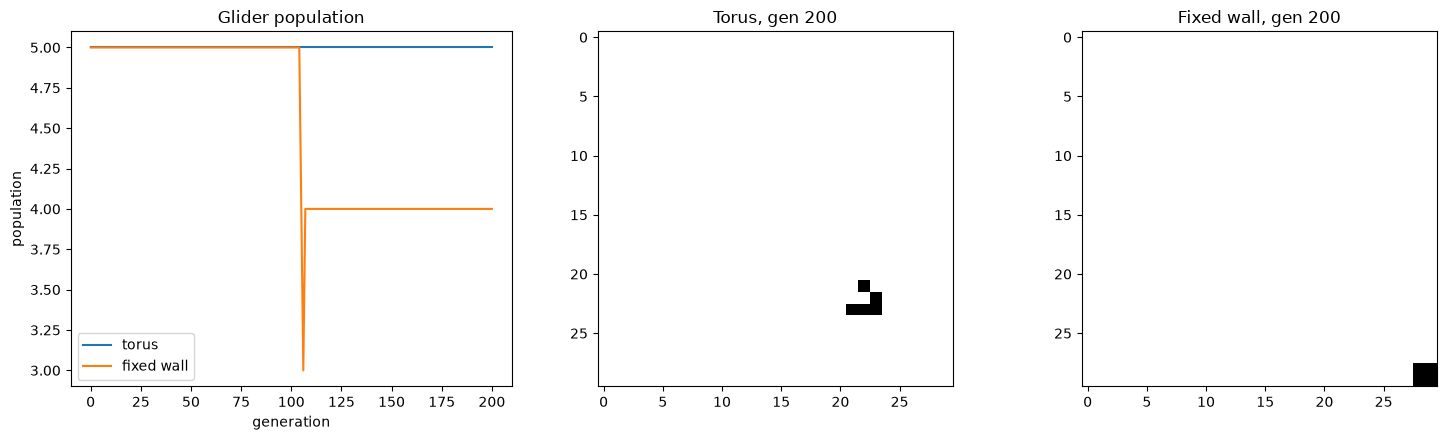

In [18]:
GENS = 200
g0 = np.zeros((30, 30), dtype=int)
g0[1:4, 1:4] = rle_decode(GLIDER)              # heading down-right, toward the corner

glider_torus, pop_torus = run(g0, life_step, GENS)
glider_fixed, pop_fixed = run(g0, life_step_fixed, GENS)

print("Torus : population always 5:", bool(np.all(pop_torus == 5)))
frozen_from = int(np.flatnonzero(pop_fixed != 4)[-1] + 1)
print("Fixed : population", pop_fixed[0], "->", pop_fixed[-1], "| frozen at 4 from gen", frozen_from)
print("Fixed : surviving cells", np.argwhere(glider_fixed).tolist())

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].plot(pop_torus, label="torus")
axes[0].plot(pop_fixed, label="fixed wall")
axes[0].set(xlabel="generation", ylabel="population", title="Glider population")
axes[0].legend()
axes[1].imshow(glider_torus, cmap="binary")
axes[1].set_title(f"Torus, gen {GENS}")
axes[2].imshow(glider_fixed, cmap="binary")
axes[2].set_title(f"Fixed wall, gen {GENS}")
fig.tight_layout()
fig.savefig("fig4_glider_vs_wall.png", dpi=150)
plt.show()

On the torus the glider re-enters on the far side and keeps its 5 cells. At the fixed wall it is
destroyed and leaves a 2×2 block in the corner: the population drops from 5 to 4 and stays there.

## Task 2.2 — The gun and the wall

Torus population every 30 gens: [36, 41, 46, 51, 56, 61, 66, 71, 76, 81, 86]
Fixed population every 30 gens: [36, 41, 46, 51, 56, 61, 65, 61, 65, 61, 65]
Fixed wall: gun intact for all 300 generations: True


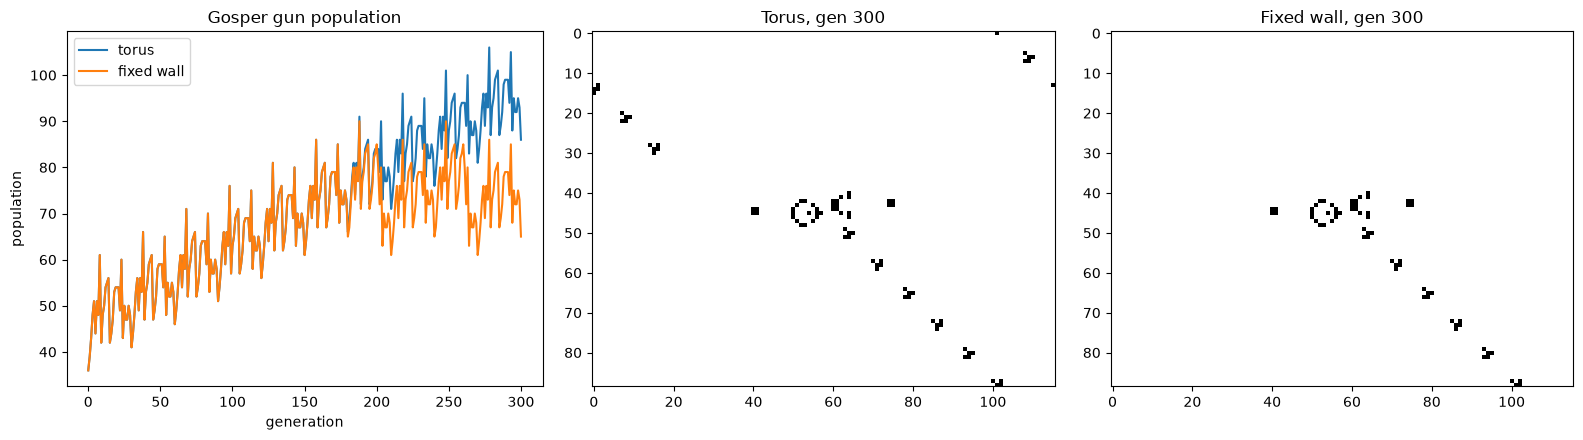

In [19]:
GENS = 300
gun = rle_decode(GUN)
G0 = np.pad(gun, 40)

gun_torus, pop_gun_torus = run(G0, life_step, GENS)
gun_fixed, pop_gun_fixed = run(G0, life_step_fixed, GENS)

# undisturbed reference: same gun on a grid too large for any glider to come back
ref = np.pad(gun, 400)
box, ref_box = (slice(38, 52), slice(38, 79)), (slice(398, 412), slice(398, 439))
g, r, gun_intact = G0.copy(), ref.copy(), True
for _ in range(GENS):
    g, r = life_step_fixed(g), life_step_fixed(r)
    gun_intact &= np.array_equal(g[box], r[ref_box])

print("Torus population every 30 gens:", pop_gun_torus[::30].tolist())
print("Fixed population every 30 gens:", pop_gun_fixed[::30].tolist())
print("Fixed wall: gun intact for all", GENS, "generations:", bool(gun_intact))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(pop_gun_torus, label="torus")
axes[0].plot(pop_gun_fixed, label="fixed wall")
axes[0].set(xlabel="generation", ylabel="population", title="Gosper gun population")
axes[0].legend()
axes[1].imshow(gun_torus, cmap="binary")
axes[1].set_title(f"Torus, gen {GENS}")
axes[2].imshow(gun_fixed, cmap="binary")
axes[2].set_title(f"Fixed wall, gen {GENS}")
fig.tight_layout()
fig.savefig("fig5_gosper_gun_vs_wall.png", dpi=150)
plt.show()

On the torus the population grows by 5 every 30 generations. With the fixed wall each glider crashes
into the bottom-right corner, and the population levels off at about 61–65 instead of growing. The
wrecks pile up as debris along the wall. None of it travels back up the glider lane, so the gun is
never disturbed.

## Task 2.3 — HighLife (B36/S23) replicator

Generation 0 : 12 cells
Generation 12: 24 cells


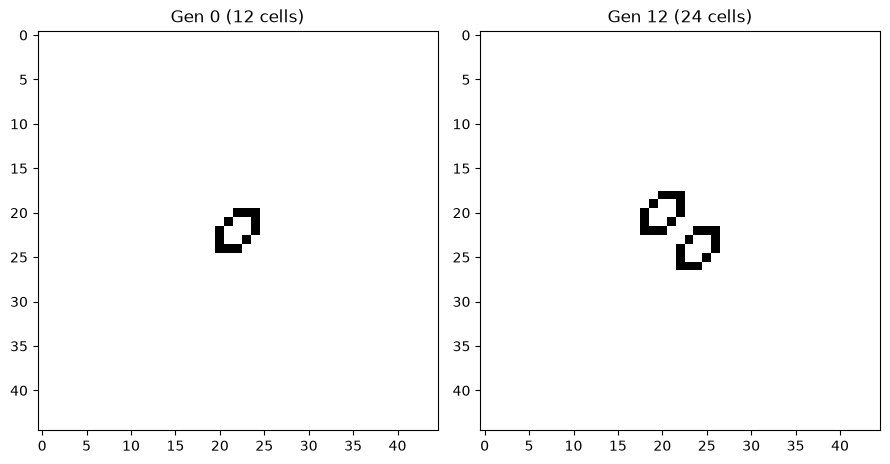

In [20]:
R0 = np.pad(rle_decode(REPLICATOR), 20)
R12, pop_rep = run(R0, life_step, 12, birth=(3, 6))   # the one-line change: birth on 3 or 6

print("Generation 0 :", pop_rep[0], "cells")
print("Generation 12:", pop_rep[12], "cells")

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(R0, cmap="binary")
axes[0].set_title(f"Gen 0 ({pop_rep[0]} cells)")
axes[1].imshow(R12, cmap="binary")
axes[1].set_title(f"Gen 12 ({pop_rep[12]} cells)")
fig.tight_layout()
fig.savefig("fig6_highlife_replicator.png", dpi=150)
plt.show()

The replicator keeps copying itself and spreading outward, so it is bound to reach the edge, where it
either wraps round and collides with its own copies or is cut off by the wall; a still life never
moves, so it never feels the boundary.

# Part 3 — Track A: Forest fire (SOC)

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Listing 4.3 (verbatim)
EMPTY, TREE, FIRE = 0, 1, 2

def forest_step(g, p_grow, p_light, rng):
    """One synchronous update of the Drossel-Schwabl forest-fire model."""
    burn_nb = np.zeros(g.shape, dtype=bool)   # any burning vN neighbour?
    for di, dj in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
        burn_nb |= np.roll(np.roll(g == FIRE, di, 0), dj, 1)  # periodic boundaries
    new = g.copy()
    new[g == FIRE] = EMPTY                    # 1. burning -> empty
    catch = (g == TREE) & (burn_nb | (rng.random(g.shape) < p_light))
    new[catch] = FIRE                         # 2.-3. spread + lightning
    grow = (g == EMPTY) & (rng.random(g.shape) < p_grow)
    new[grow] = TREE                          # 4. regrowth
    return new

rng = np.random.default_rng(1)
g = (rng.random((200, 200)) < 0.55).astype(int)  # 55% initial tree cover
burning = []
for _ in range(400):
    g = forest_step(g, p_grow=0.01, p_light=0.0002, rng=rng)
    burning.append((g == FIRE).mean())
print(f"final tree fraction = {(g == TREE).mean():.3f}; "
      f"mean burning fraction = {np.mean(burning):.4f}")

final tree fraction = 0.403; mean burning fraction = 0.0066


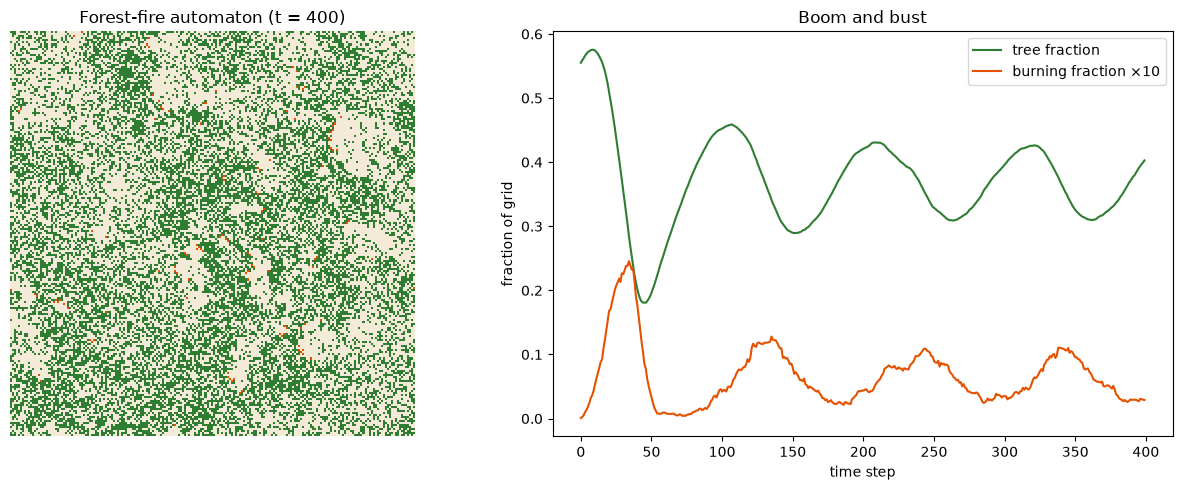

In [22]:
def simulate(p_grow=0.01, p_light=0.0002, seed=1, n=200, steps=400):
    """Listing 4.3 as a function: returns final grid and tree / burning time series."""
    rng = np.random.default_rng(seed)
    g = (rng.random((n, n)) < 0.55).astype(int)
    trees, burning = [], []
    for _ in range(steps):
        g = forest_step(g, p_grow, p_light, rng)
        trees.append((g == TREE).mean())
        burning.append((g == FIRE).mean())
    return g, np.array(trees), np.array(burning)


FOREST_CMAP = ListedColormap(["#f3ead8", "#2e7d32", "#e65100"])   # empty, tree, fire

g400, trees, burning = simulate()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(g400, cmap=FOREST_CMAP, vmin=0, vmax=2, interpolation="nearest")
axes[0].set_title("Forest-fire automaton (t = 400)")
axes[0].axis("off")
axes[1].plot(trees, color="#2e7d32", label="tree fraction")
axes[1].plot(10 * burning, color="#e65100", label="burning fraction ×10")
axes[1].set(xlabel="time step", ylabel="fraction of grid", title="Boom and bust")
axes[1].legend()
fig.tight_layout()
fig.savefig("fig7_forest_fire_snapshot.png", dpi=150)
plt.show()

## (i) Double p, then double f

run                          mean tree      tree swing  mean burning  period
baseline  p=0.01, f=0.0002       0.371   0.289–0.459        0.0063     104
double p  p=0.02, f=0.0002       0.394   0.285–0.476        0.0118      63
double f  p=0.01, f=0.0004       0.352   0.295–0.422        0.0065      97


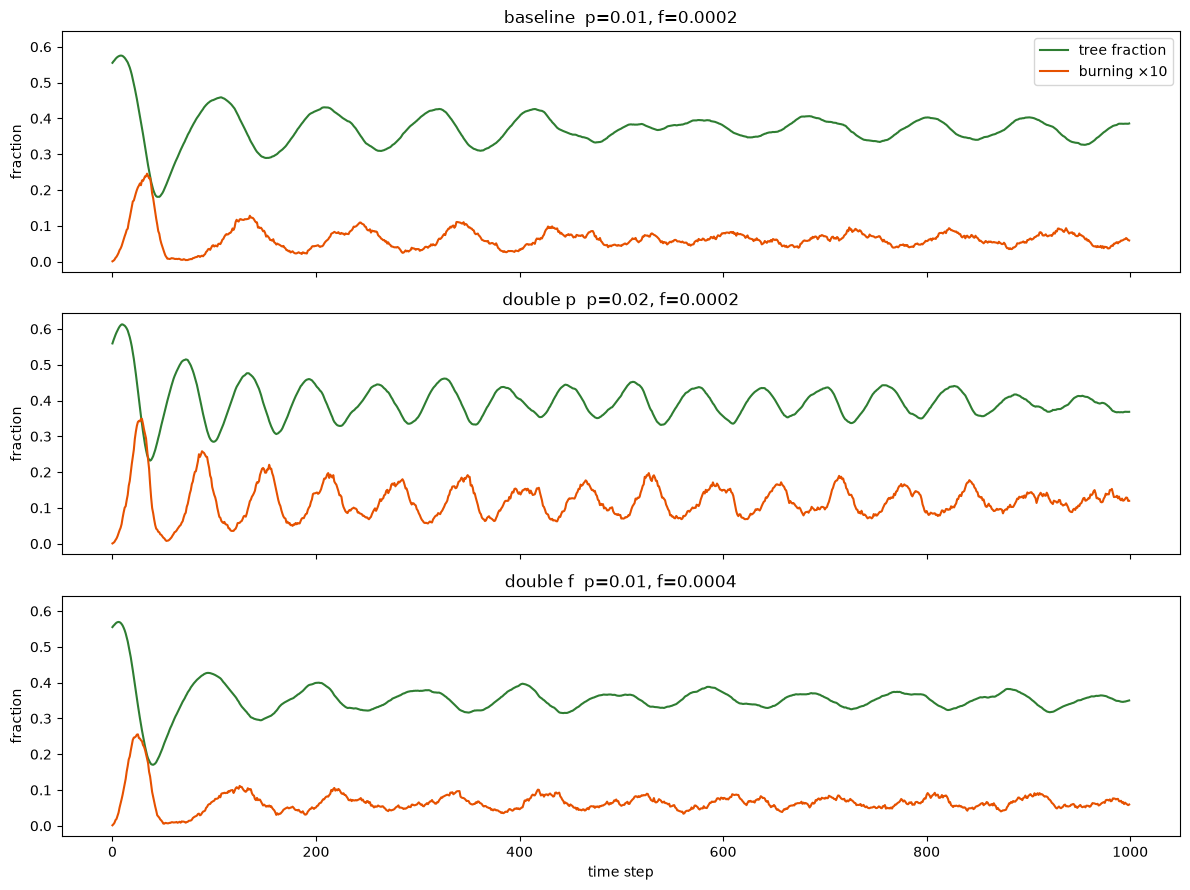

In [23]:
def cycle_period(x, skip=100):
    """Dominant boom-and-bust period from the autocorrelation of the tree fraction."""
    x = x[skip:] - x[skip:].mean()
    ac = np.correlate(x, x, "full")[len(x) - 1:]
    first_neg = np.argmax(ac < 0)
    return first_neg + np.argmax(ac[first_neg:])

STEPS = 1000
runs = {
    "baseline  p=0.01, f=0.0002": (0.01, 0.0002),
    "double p  p=0.02, f=0.0002": (0.02, 0.0002),
    "double f  p=0.01, f=0.0004": (0.01, 0.0004),
}

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, sharey=True)
print(f"{'run':<28}{'mean tree':>10}{'tree swing':>16}{'mean burning':>14}{'period':>8}")
for ax, (name, (p, f)) in zip(axes, runs.items()):
    _, tr, bu = simulate(p, f, steps=STEPS)
    s = tr[100:]
    print(f"{name:<28}{s.mean():>10.3f}{s.min():>8.3f}–{s.max():.3f}{bu[100:].mean():>14.4f}{cycle_period(tr):>8d}")
    ax.plot(tr, color="#2e7d32", label="tree fraction")
    ax.plot(10 * bu, color="#e65100", label="burning ×10")
    ax.set_title(name)
    ax.set_ylabel("fraction")
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("time step")
fig.tight_layout()
fig.savefig("fig8_forest_fire_p_f_doubling.png", dpi=150)
plt.show()

**Doubling p** makes trees grow back twice as fast. The boom-and-bust cycle speeds up (period about
104 → 63 steps), the burning fraction almost doubles, and the forest stays slightly denser on average.
**Doubling f** leaves the period about the same but flattens the cycle: the tree fraction swings over a
narrower range and settles at a lower mean. Lightning strikes more often, so the forest catches fire
before it can build up to the dense peaks that feed the big fires.

## (ii) Fire size per ignition event — CCDF

fires recorded: 4460 | mean size 105.8 (p/f = 50) | median 10 | largest 9283 cells


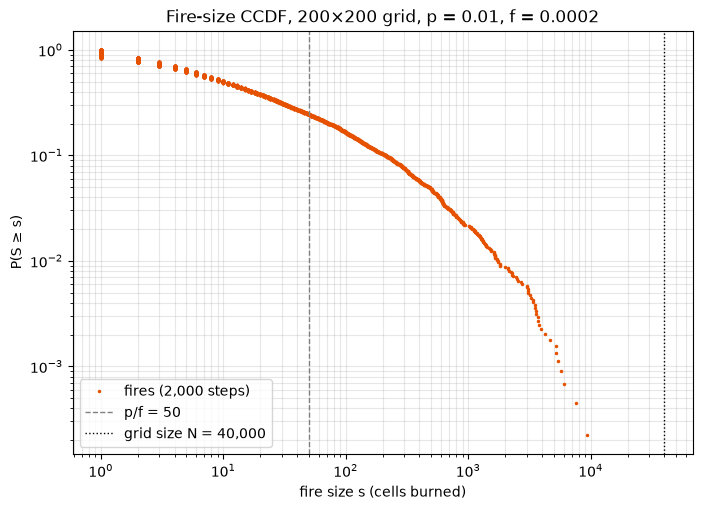

In [24]:
def fire_sizes(p_grow=0.01, p_light=0.0002, seed=1, n=200, steps=2000, warmup=200):
    """Same dynamics as forest_step, but tracks which lightning strike every burning cell belongs to.

    Fire size = total cells burned by one ignition, from strike until its last cell goes out
    (fires that meet are merged). Fires started during the warm-up or still burning at the end
    are excluded.
    """
    rng = np.random.default_rng(seed)
    g = (rng.random((n, n)) < 0.55).astype(int)
    label = np.zeros(g.shape, dtype=int)             # fire id of each burning cell (0 = none)
    parent, size, start = [0], [0], [0]              # union-find over fire ids

    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a

    for t in range(warmup + steps):
        fire = g == FIRE
        nb_labels = [np.roll(np.roll(label * fire, di, 0), dj, 1)
                     for di, dj in [(-1, 0), (1, 0), (0, -1), (0, 1)]]
        burn_nb = np.any([L > 0 for L in nb_labels], axis=0)
        new = g.copy()
        new[fire] = EMPTY
        catch = (g == TREE) & (burn_nb | (rng.random(g.shape) < p_light))
        new[catch] = FIRE
        grow = (g == EMPTY) & (rng.random(g.shape) < p_grow)
        new[grow] = TREE

        new_label = np.zeros_like(label)
        spread = catch & burn_nb                     # caught from a neighbour: join its fire
        inherit = np.max(nb_labels, axis=0)
        for L in nb_labels:                          # two fires meeting -> merge them
            meet = spread & (L > 0) & (L != inherit)
            for a, b in zip(L[meet], inherit[meet]):
                ra, rb = find(a), find(b)
                if ra != rb:
                    parent[ra] = rb
                    size[rb] += size[ra]
                    start[rb] = min(start[rb], start[ra])
        new_label[spread] = inherit[spread]
        for idx in np.argwhere(catch & ~burn_nb):    # lightning: a new fire
            parent.append(len(parent)); size.append(0); start.append(t)
            new_label[tuple(idx)] = len(parent) - 1
        ids, counts = np.unique(new_label[catch], return_counts=True)
        for fid, cnt in zip(ids, counts):
            size[find(fid)] += cnt
        g, label = new, new_label

    still_burning = {find(f) for f in np.unique(label[g == FIRE])}
    roots = {find(f) for f in range(1, len(parent))}
    return np.array([size[r] for r in roots if r not in still_burning and start[r] >= warmup])


sizes = fire_sizes()
p, f, N = 0.01, 0.0002, 200 * 200
print(f"fires recorded: {len(sizes)} | mean size {sizes.mean():.1f} (p/f = {p / f:.0f}) | "
      f"median {np.median(sizes):.0f} | largest {sizes.max()} cells")

s_sorted = np.sort(sizes)
ccdf = 1.0 - np.arange(len(s_sorted)) / len(s_sorted)        # P(S >= s)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.loglog(s_sorted, ccdf, ".", ms=3, color="#e65100", label="fires (2,000 steps)")
ax.axvline(p / f, color="grey", ls="--", lw=1, label="p/f = 50")
ax.axvline(N, color="black", ls=":", lw=1, label="grid size N = 40,000")
ax.set(xlabel="fire size s (cells burned)", ylabel="P(S ≥ s)",
       title="Fire-size CCDF, 200×200 grid, p = 0.01, f = 0.0002")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
fig.savefig("fig9_fire_size_ccdf.png", dpi=150)
plt.show()

**Observation.** Most fires are tiny (median 10 cells) but a few burn thousands of cells; the
largest burns about 9,300 cells, nearly a quarter of the forest. That heavy tail is the signature of
self-organised criticality. The CCDF is not straight on log–log axes: its local slope steepens steadily
from about −0.4 for small fires (3–30 cells) to −0.9 at 100–1000 cells and −1.6 beyond 1,000 cells.
Above about 1,000 cells the curve bends sharply down and cuts off well before the grid size
(N = 40,000). A 200 × 200 forest cannot hold the very large fires a power law would predict, and only
96 of the 4,460 fires exceed 1,000 cells. Fitting a single straight line through every point would
therefore be dishonest: it would average the shallow small-fire region together with the finite-size
cutoff and report one exponent that the data never actually show (§4.5's finite-size caveat). An
honest exponent needs a much larger grid and a clearly identified scaling region.

# Part 4 — Animation studio: p5.js

## Task 4.1 — Remix the worked example

**Sketch:** https://editor.p5js.org/chanurashmika.edu/sketches/l6I8cti70

Coding Train Game of Life (Coding Challenge #85) with three edits, on a 30 × 30 grid:

1. **B** toggles `countNeighbors` between the modulo wrap (torus) and fixed dead edges (out-of-range neighbours skipped).
2. HighLife: birth condition extended to `neighbors == 3 || (highLife && neighbors == 6)`; **H** toggles the rule, **E** seeds the replicator.
3. Cells coloured by age: newborns bright yellow, cells alive 60+ generations fade to dark blue.

Other keys: **G** glider, **R** random soup, **P** pause, **N** single step, **C** clear.

**Checks against Part 2:**

| Run | Result |
|---|---|
| Glider, torus | population 5 forever, re-enters on the far side |
| Glider, fixed edges | destroyed at the corner; 2×2 block remains, population 5 → 4 (gen 107) |
| HighLife replicator | 12 cells → 24 cells at generation 12 |

In the random soup, the dark-blue cells are the old still lifes (blocks, beehives) and blinkers, while the bright cells mark where activity is still going on.

## Task 4.2 — Animate one of my models: elementary CA

**Sketch:** https://editor.p5js.org/chanurashmika.edu/sketches/DolJWI9A3

Listing 4.1 (Part 1) converted to p5.js, built on the lab sheet's Route 2 starter: one CA row per frame, two-grid update, 201 cells, fixed dead edges by default. Buttons select Rules 30 / 90 / 110 / 184, toggle the boundary, restart, and run **Verify**.

**Verification check passed:** Listing 4.1 cumulative counts (201 cells, 100 steps, fixed edges)

| Rule | 30 | 90 | 110 | 184 |
|---|---|---|---|---|
| p5.js sketch | 5196 | 1251 | 2876 | 100 |
| Python (Part 1) | 5196 | 1251 | 2876 | 100 |

With fixed edges, Rule 184's seed also disappears at row 100, matching Task 1.1.

# Findings summary

What surprised me most was how much the boundary matters even though it is only one line of code. A glider does not just vanish at a fixed wall: it leaves a 2×2 block behind (population 5 → 4). Rule 30's fixed and periodic runs are identical for exactly 100 steps and then diverge completely. The light cone makes the boundary invisible until the pattern reaches it.

The most consequential boundary effect was Rule 184. On a ring it conserves its single "car" forever, but with fixed edges the car is destroyed at step 100. That breaks the conservation law that makes Rule 184 a traffic model.

I used an AI assistant for the p5.js conversion. On the first try the sketch crashed with `TypeError: Cannot redefine property: step`: its function name `step` clashed with a built-in in p5.js 2.x. I caught this from the editor console and renamed the function. Its toggles were also keyboard-only, which I only noticed when no key presses reached the console, so on-screen buttons were added. Neither sketch updates the grid in place or changes the boundary silently. I confirmed this by checking the glider, gun and replicator numbers and the 5196 / 1251 / 2876 / 100 counts against my Python results.